In [1]:
%pip install -q pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


# 03. Portfolio risk metrics: return, risk, and diversification

A portfolio is just a mix of investments held together. Three ideas
carry this whole notebook.

First, volatility. We already met it in notebook 02. It is the spread
of returns, annualized. Higher volatility means a bumpier ride.

Second, return per unit of risk. Take the average yearly return and
divide it by volatility. If two mixes earn the same return, the one with
lower volatility has a higher return per unit of risk, which means it
earned that return with less bumpiness. This is a Sharpe style idea.
A true Sharpe ratio subtracts a safe rate, like a Treasury bill yield,
before dividing. Here we report return per unit of risk in plain form
and we say so, so nobody mistakes it for a formal Sharpe ratio.

Third, diversification benefit. Diversification means holding things
that do not always move together. If you average the volatility of each
holding on its own, and then measure the volatility of the mix, the mix
is usually less bumpy than the average holding. The gap between those
two numbers is the diversification benefit. It is small when holdings
move together, and larger when they move differently.

Important limit: this notebook uses three US stock indexes only, the
S and P 500, the Nasdaq Composite, and the Dow Jones Industrial
Average, from November 2016 to October 2026, because that is the window
where the FRED downloads for all three overlap. Three stock indexes
that track the same US market will move together a lot, so we expect
only a small diversification benefit here. That is a finding, not a
failure. It shows why real diversification usually needs different
kinds of assets, not just different stock indexes.

Nothing here is investment advice, and nothing here is a recommended
portfolio. We are describing past bumpiness, not predicting future returns.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
ROOT = Path("..").resolve()
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
PROC = ROOT / "data" / "processed"
print("Charts will be saved to:", CHARTS)

Charts will be saved to: /home/hatch/workspace/repo-builds/finance-analytics/charts


In [3]:
port = pd.read_csv(PROC / "portfolio_inputs_daily.csv", parse_dates=["date"])
ret_cols = ["fred_sp500_ret", "nasdaq_ret", "fred_dow_ret"]
rets = port[ret_cols].dropna()
print("Window:", port["date"].min().date(), "to", port["date"].max().date(), "with", len(rets), "daily returns")
corr = rets.corr()
print()
print("Correlation of daily returns (1 means they move together perfectly):")
print(corr.round(3).to_string())

Window: 2016-11-03 to 2026-10-29 with 2509 daily returns

Correlation of daily returns (1 means they move together perfectly):
                fred_sp500_ret  nasdaq_ret  fred_dow_ret
fred_sp500_ret           1.000       0.949         0.943
nasdaq_ret               0.949       1.000         0.819
fred_dow_ret             0.943       0.819         1.000


In [4]:
import numpy as np
stats = []
labels = {"fred_sp500_ret": "S and P 500", "nasdaq_ret": "Nasdaq", "fred_dow_ret": "Dow"}
for col in ret_cols:
    r = rets[col]
    ann_ret = (1 + r).prod() ** (252 / len(r)) - 1
    ann_vol = r.std() * np.sqrt(252)
    stats.append({"asset": labels[col], "ann_return_pct": ann_ret * 100, "ann_vol_pct": ann_vol * 100,
                  "return_per_unit_risk": ann_ret / ann_vol})
equal = rets.mean(axis=1)
ann_ret_eq = (1 + equal).prod() ** (252 / len(equal)) - 1
ann_vol_eq = equal.std() * np.sqrt(252)
stats.append({"asset": "Equal mix of the three", "ann_return_pct": ann_ret_eq * 100,
              "ann_vol_pct": ann_vol_eq * 100, "return_per_unit_risk": ann_ret_eq / ann_vol_eq})
stats_df = pd.DataFrame(stats)
print(stats_df.round(2).to_string(index=False))
avg_single_vol = stats_df.iloc[:3]["ann_vol_pct"].mean()
print()
print("Average single index volatility:", round(avg_single_vol, 2), "percent")
print("Equal mix volatility:", round(ann_vol_eq * 100, 2), "percent")
print("Diversification benefit:", round(avg_single_vol - ann_vol_eq * 100, 2), "percentage points")

                 asset  ann_return_pct  ann_vol_pct  return_per_unit_risk
           S and P 500           14.03        18.09                  0.78
                Nasdaq           17.96        22.20                  0.81
                   Dow           11.36        17.64                  0.64
Equal mix of the three           14.58        18.67                  0.78

Average single index volatility: 19.31 percent
Equal mix volatility: 18.67 percent
Diversification benefit: 0.64 percentage points


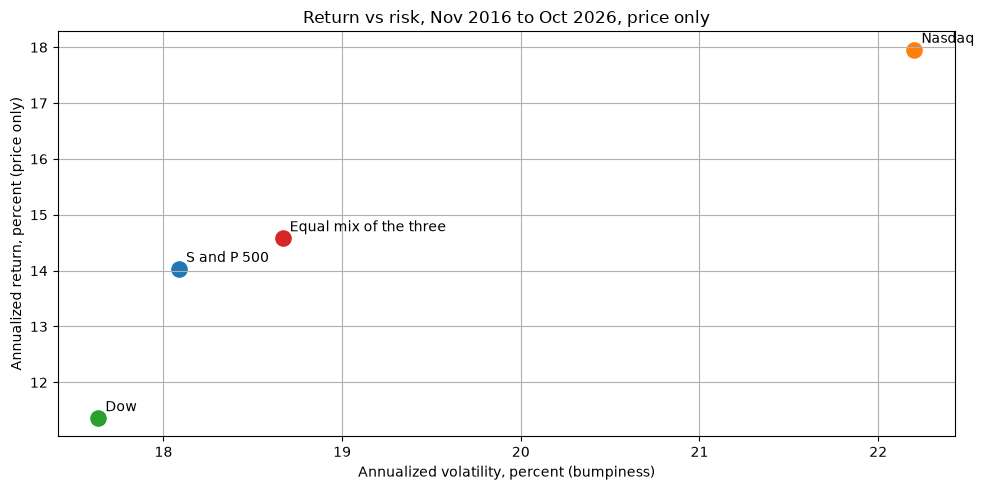

In [5]:
fig, ax = plt.subplots()
for _, row in stats_df.iterrows():
    ax.scatter(row["ann_vol_pct"], row["ann_return_pct"], s=120)
    ax.annotate(row["asset"], (row["ann_vol_pct"], row["ann_return_pct"]), xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("Annualized volatility, percent (bumpiness)")
ax.set_ylabel("Annualized return, percent (price only)")
ax.set_title("Return vs risk, Nov 2016 to Oct 2026, price only")
plt.tight_layout()
plt.savefig(CHARTS / "03_risk_return.png", dpi=150)
plt.show()

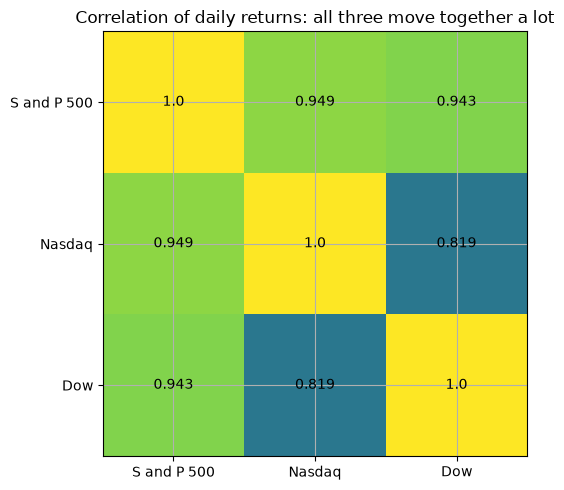

In [6]:
fig, ax = plt.subplots()
im = ax.imshow(corr.values, vmin=0.7, vmax=1.0)
ax.set_xticks(range(len(ret_cols)))
ax.set_yticks(range(len(ret_cols)))
ax.set_xticklabels(["S and P 500", "Nasdaq", "Dow"])
ax.set_yticklabels(["S and P 500", "Nasdaq", "Dow"])
for i in range(len(ret_cols)):
    for j in range(len(ret_cols)):
        ax.text(j, i, round(corr.values[i, j], 3), ha="center", va="center")
ax.set_title("Correlation of daily returns: all three move together a lot")
plt.tight_layout()
plt.savefig(CHARTS / "03_correlation.png", dpi=150)
plt.show()

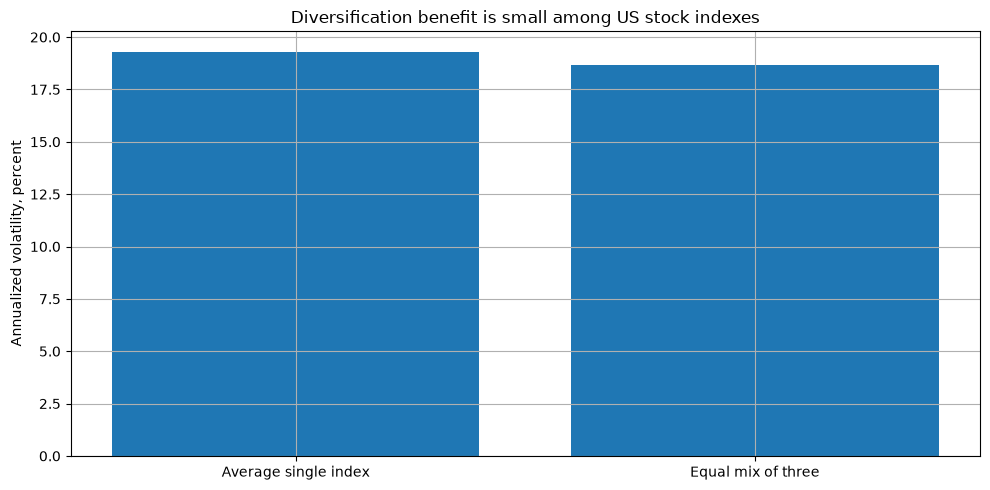

In [7]:
fig, ax = plt.subplots()
ax.bar(["Average single index", "Equal mix of three"], [avg_single_vol, ann_vol_eq * 100])
ax.set_ylabel("Annualized volatility, percent")
ax.set_title("Diversification benefit is small among US stock indexes")
plt.tight_layout()
plt.savefig(CHARTS / "03_diversification.png", dpi=150)
plt.show()

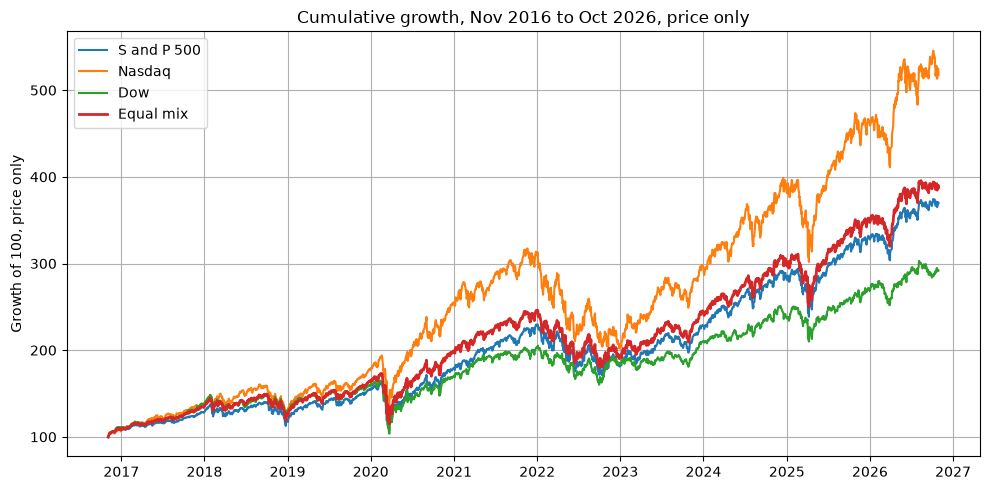

In [8]:
cum = (1 + rets).cumprod() * 100
cum_eq = (1 + equal).cumprod() * 100
fig, ax = plt.subplots()
ax.plot(port["date"].iloc[1:], cum["fred_sp500_ret"], label="S and P 500")
ax.plot(port["date"].iloc[1:], cum["nasdaq_ret"], label="Nasdaq")
ax.plot(port["date"].iloc[1:], cum["fred_dow_ret"], label="Dow")
ax.plot(port["date"].iloc[1:], cum_eq, label="Equal mix", linewidth=2)
ax.set_ylabel("Growth of 100, price only")
ax.set_title("Cumulative growth, Nov 2016 to Oct 2026, price only")
ax.legend()
plt.tight_layout()
plt.savefig(CHARTS / "03_portfolio_cumulative.png", dpi=150)
plt.show()

## What we learned, in plain words

Over this window, the Nasdaq had the highest return and the highest
volatility, the Dow had the lowest return and the lowest volatility,
and the equal mix sat in the middle on both. Correlations were high,
from 0.82 to 0.95, so the diversification benefit was only about 0.6
percentage points of volatility. That is the honest result: mixing three
US stock indexes smooths the ride only a little, because they mostly
rise and fall together.

If someone promises a big diversification benefit from holding three
similar stock funds, ask what is actually different about them. Real
diversification needs assets that behave differently in stress, and
that claim needs to be tested with data, not assumed.